# 4. Massive black hole binaries: search, likelihoods and parameter estimation

**Goal:** reconstruct an MBHB with $\mathcal F$-statistics + differential
evolution, test heterodyned against full likelihoods, then use nessai.

**Data:** the  **TDC II-0.2** data. **Optimal combined A/E SNR ≈ 1090.7**. 

In [1]:
%matplotlib inline
# Paths and plotting defaults only; the scientific workflow is below.
from tutorial_tools.common import DATA, OUTPUT, ORBIT, DAY, load_arrays, inner
import json
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Image

# Parallel workers, as in the Triangle-BBH CPU examples: the "fork" start
# method lets the notebook-defined likelihood class reach the child processes.
import multiprocessing
if multiprocessing.get_start_method(allow_none=True) != "fork":
    multiprocessing.set_start_method("fork", force=True)
NPROC = multiprocessing.cpu_count()
print("CPU cores:", NPROC, "| start method:", multiprocessing.get_start_method())


CPU cores: 12 | start method: fork


In [2]:
RUN_SEARCH = True 
RUN_NESSAI = False
a = load_arrays("mbhb_tdc_cut.npz")
meta = json.loads((DATA/"mbhb_tdc_cut.json").read_text())
f, data, weight = a["frequency_Hz"], a["data_ae"], a["weight"]
fit = meta["searched_parameters"].copy()
print("Optimal A/E SNR ≈", meta["optimal_AE_SNR"])
print("Duration [day]:", meta["Tobs_seconds"]/DAY, "; retained bins:", len(f))

Optimal A/E SNR ≈ 1090.664
Duration [day]: 4.999884259259259 ; retained bins: 4298


## 1. Set up response

In [3]:
from Triangle.Orbit import Orbit
from Triangle_BBH.Waveform import WaveformGeneratorFRef
from Triangle_BBH.Response import FDTDIResponseGeneratorFRef
from Triangle_BBH.Utils import FstatisticsFref, Likelihood, ParamDict2ParamArrFref

response = FDTDIResponseGeneratorFRef(orbit_class=Orbit(OrbitDir=str(ORBIT)),
                                    waveform_generator=WaveformGeneratorFRef(mode="primary"))
options = meta["response_options"].copy()
options["modes"] = [(2, 2)]
inverse_covariance = np.zeros((len(f), 2, 2))
inverse_covariance[:, 0, 0], inverse_covariance[:, 1, 1] = weight
search_options = {**options, "interpolation_method": "cubic"}
fstat = FstatisticsFref(response, f, data, inverse_covariance, search_options, use_gpu=False)

PyCBC.libutils: pkg-config call failed, setting NO_PKGCONFIG=1


No pyseobnr.
no cupy 
no cupy
No CuPy or GPU PhenomHM module.
has BBHx waveform


## 2. Search seven intrinsic coordinates
The $\mathcal F$-statistic maximises four linear amplitudes analytically.
Differential evolution searches seven intrinsic parameters over these ranges:

- $\log_{10}\mathcal M_c \in [5, 7]$, i.e. $\mathcal M_c$ from $10^5$ to
  $10^7\,M_\odot$ (the searched value is $3.0\times10^6\,M_\odot$).
- Mass ratio $q \in [0.01, 0.99]$.
- Aligned spins $\chi_{1z}, \chi_{2z} \in [-0.9, 0.9]$ each.
- Reference time $t_{\rm ref} \in [22.50, 27.50]$ day — the whole five-day cut
  around its midpoint.
- Longitude $\lambda \in [0, 2\pi)$ rad.
- $\sin\beta \in [-1, 1]$, i.e. the full sky ($|\beta| \le 90^\circ$).


In [4]:
from scipy.optimize import differential_evolution
from tqdm.auto import tqdm
ranges = np.array([[5, 7], [0.01, 0.99], [-0.9, 0.9], [-0.9, 0.9],
                   [options["tmin"], options["tmax"]], [0, 2*np.pi], [-1, 1]])

def search_cost(x):
    p = fstat.IntParamArr2ParamDict(ranges[:, 0]+x*np.ptp(ranges, axis=1))
    try:
        return -float(np.asarray(fstat.calculate_Fstat(p)).item())
    except np.linalg.LinAlgError:
        return np.inf

def unpack(x):
    """Unit-cube coordinates -> intrinsic parameters."""
    return fstat.IntParamArr2ParamDict(ranges[:, 0]+x*np.ptp(ranges, axis=1))

history = {"F": [], "chirp_mass": [], "mass_ratio": []}   # per generation

intrinsic = {name: fit[name] for name in fstat.intrinsic_parameter_names}
if RUN_SEARCH:
    bar = tqdm(total=1000, desc="MBHB search", unit="gen")
    def callback(xk, convergence=None):
        p, F = unpack(xk), -search_cost(xk)      # best member so far
        history["F"].append(F)
        history["chirp_mass"].append(p["chirp_mass"])
        history["mass_ratio"].append(p["mass_ratio"])
        bar.set_postfix_str(f"F={F:9.1f}  Mc={p['chirp_mass']:.2e}  "
                            f"q={p['mass_ratio']:.3f}  conv={convergence:.1e}")
        bar.update(1)
        return False                             # never stop early
    result = differential_evolution(search_cost, [(0, 1)]*7, seed=20261108,
                                    strategy="best1exp", popsize=35, maxiter=1000,
                                    mutation=(0.4, 0.95), recombination=0.7,
                                    tol=1e-6, polish=False, workers=-1,
                                    callback=callback)
    bar.close()
    intrinsic = unpack(result.x)
    print(result.message)
    print(f"  best F = {-result.fun:.1f} after {result.nit} generations: "
          f"chirp_mass = {intrinsic['chirp_mass']:.4e} Msun, "
          f"mass_ratio = {intrinsic['mass_ratio']:.4f}, "
          f"spins = ({intrinsic['spin_1z']:.3f}, {intrinsic['spin_2z']:.3f}), "
          f"t_ref = {intrinsic['reference_time']:.4f} day, "
          f"lon = {intrinsic['longitude']:.3f}, lat = {intrinsic['latitude']:.3f}")
coefficients = fstat.calculate_Fstat(intrinsic, return_a=True)
fit = {**intrinsic, **fstat.a_to_extrinsic(coefficients)}
print("F at the completed search:", float(np.asarray(fstat.calculate_Fstat(intrinsic)).item()))


MBHB search:   0%|          | 0/1000 [00:00<?, ?gen/s]

/Users/taijidatacenter/miniconda3/envs/tri_env/lib/python3.9/site-packages/scipy/optimize/_differentialevolution.py:487: UserWarning: differential_evolution: the 'workers' keyword has overridden updating='immediate' to updating='deferred'
  with DifferentialEvolutionSolver(func, bounds, args=args,


Optimization terminated successfully.
  best F = 594051.9 after 161 generations: chirp_mass = 2.9961e+06 Msun, mass_ratio = 0.2506, spins = (0.392, 0.629), t_ref = 24.9976 day, lon = 4.678, lat = 0.208
F at the completed search: 594051.9087168314


### Search convergence
Best member of each generation: the $\mathcal F$-statistic (left) and the
chirp mass it corresponds to (right, dotted line = searched value). The
staircase shows when the population stops improving; `conv` in the progress
bar is the same DE convergence measure that `tol` acts on.


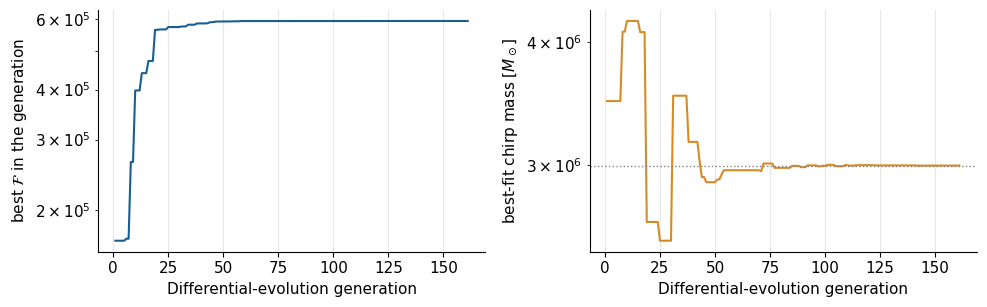

In [5]:
# Search progress: best F and best-fit masses of each generation.
if history["F"]:
    gen = np.arange(1, len(history["F"])+1)
    fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
    ax[0].semilogy(gen, history["F"], lw=1.5, color="#185e92")
    ax[0].set(xlabel="Differential-evolution generation",
              ylabel=r"best $\mathcal{F}$ in the generation")
    ax[1].semilogy(gen, history["chirp_mass"], lw=1.5, color="#d78b25")
    ax[1].axhline(fit["chirp_mass"], color="gray", ls=":", lw=1)
    ax[1].set(xlabel="Differential-evolution generation",
              ylabel=r"best-fit chirp mass [$M_\odot$]")
    for panel in ax:
        panel.grid(which="major", alpha=0.3)
    plt.tight_layout()
else:
    print("Search skipped (RUN_SEARCH = False); enable it to record convergence.")


## 3. Reconstruct the waveform


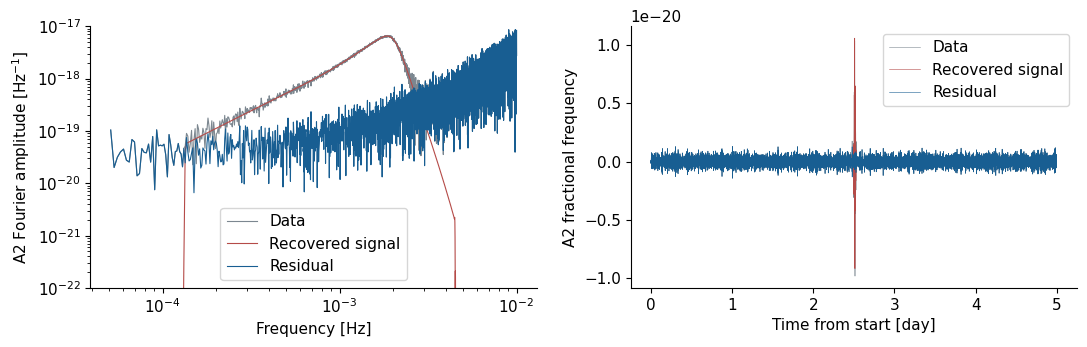

In [17]:
h_fit = np.asarray(response.Response(fit, f, **search_options))

# Time domain: inverse FFT of the retained band only. The band sets the grid:
# Nyquist 0.02 Hz -> dt ~ 50 s, and the absolute-time phase applied during
# preprocessing is removed so that the coalescence sits at the cut centre.
band_df = f[1]-f[0]
T_obs = 1/band_df
n_time = int(round(2*f[-1]/band_df))
dt_time = T_obs/n_time
t_start = options["tmin"]*DAY

def band_time_series(x):
    spectrum = np.zeros(n_time//2+1, complex)
    spectrum[np.round(f*T_obs).astype(int)] = x*np.exp(2j*np.pi*f*t_start)
    return np.fft.irfft(spectrum, n=n_time)/dt_time

t_day = np.arange(n_time)*dt_time/DAY
data_td, model_td = band_time_series(data[0]), band_time_series(h_fit[0])
residual_td = data_td-model_td

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for y, label, color in [(data[0], "Data", "#7c8790"),
                        (h_fit[0], "Recovered signal", "#b54b48"),
                        (data[0]-h_fit[0], "Residual", "#185e92")]:
    ax[0].loglog(f, abs(y), lw=0.8, label=label, color=color)
ax[0].set(xlabel="Frequency [Hz]", ylabel=r"A2 Fourier amplitude [Hz$^{-1}$]")
ax[0].set_ylim(1e-22, 1e-17)
ax[0].legend()
for y, label, color in [(data_td, "Data", "#7c8790"),
                        (model_td, "Recovered signal", "#b54b48"),
                        (residual_td, "Residual", "#185e92")]:
    ax[1].plot(t_day, y, lw=0.4, label=label, color=color)
ax[1].set(xlabel="Time from start [day]",
          ylabel="A2 fractional frequency")
ax[1].legend()
plt.tight_layout()


## 4. Full and heterodyned likelihoods

In [7]:
import time
like = Likelihood(response, f, data, inverse_covariance, options,
                  Fref_waveform=True, use_gpu=False)
start = time.perf_counter()
like.prepare_het_log_like(base_parameters=ParamDict2ParamArrFref(fit), num_het_frequency=256)
setup_seconds = time.perf_counter()-start
full = Likelihood(response, like.dense_frequency, like.dense_data,
                  like.dense_invserse_covariance_matrix, options,
                  Fref_waveform=True, use_gpu=False)
print("Dense/sparse frequency points:", len(like.dense_frequency), len(like.het_frequency))

Dense/sparse frequency points: 1868 256


### Likelihood test

In [8]:
delta_mass = np.linspace(-3, 3, 41)*meta["original_fisher_errors"]["chirp_mass"]
log_full, log_het, time_full, time_het = [], [], [], []
for delta in delta_mass:
    p = {**fit, "chirp_mass": fit["chirp_mass"]+delta}
    parameters = ParamDict2ParamArrFref(p)
    start = time.perf_counter(); log_full.append(full.full_log_like(parameters))
    time_full.append(time.perf_counter()-start)
    start = time.perf_counter(); log_het.append(like.het_log_like(parameters))
    time_het.append(time.perf_counter()-start)
log_full, log_het = np.array(log_full), np.array(log_het)
mid = len(delta_mass)//2
relative_full, relative_het = log_full-log_full[mid], log_het-log_het[mid]
difference = relative_het-relative_full
print(f"Preparation: {setup_seconds:.3f} s")
print(f"Median evaluation: full {np.median(time_full)*1000:.2f} ms; heterodyned {np.median(time_het)*1000:.2f} ms")
print("Maximum |difference| on this scan:", np.max(abs(difference)))
assert np.isfinite(difference).all()
np.savez_compressed(OUTPUT/"mbhb_full_heterodyne_test.npz", delta_mass_Msun=delta_mass,
                    full=relative_full, heterodyne=relative_het, difference=difference)

Preparation: 0.016 s
Median evaluation: full 3.58 ms; heterodyned 2.06 ms
Maximum |difference| on this scan: 0.263750520434769


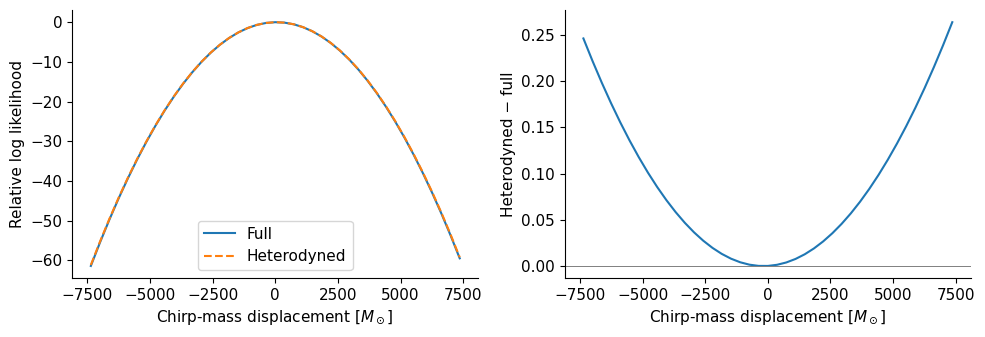

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].plot(delta_mass, relative_full, label="Full")
axes[0].plot(delta_mass, relative_het, "--", label="Heterodyned")
axes[0].set(ylabel="Relative log likelihood"); axes[0].legend()
axes[1].plot(delta_mass, difference)
axes[1].axhline(0, color="gray", lw=0.7)
axes[1].set(ylabel="Heterodyned − full")
for ax in axes: ax.set_xlabel(r"Chirp-mass displacement [$M_\odot$]")
plt.tight_layout()

## 5. Nested sampling with nessai

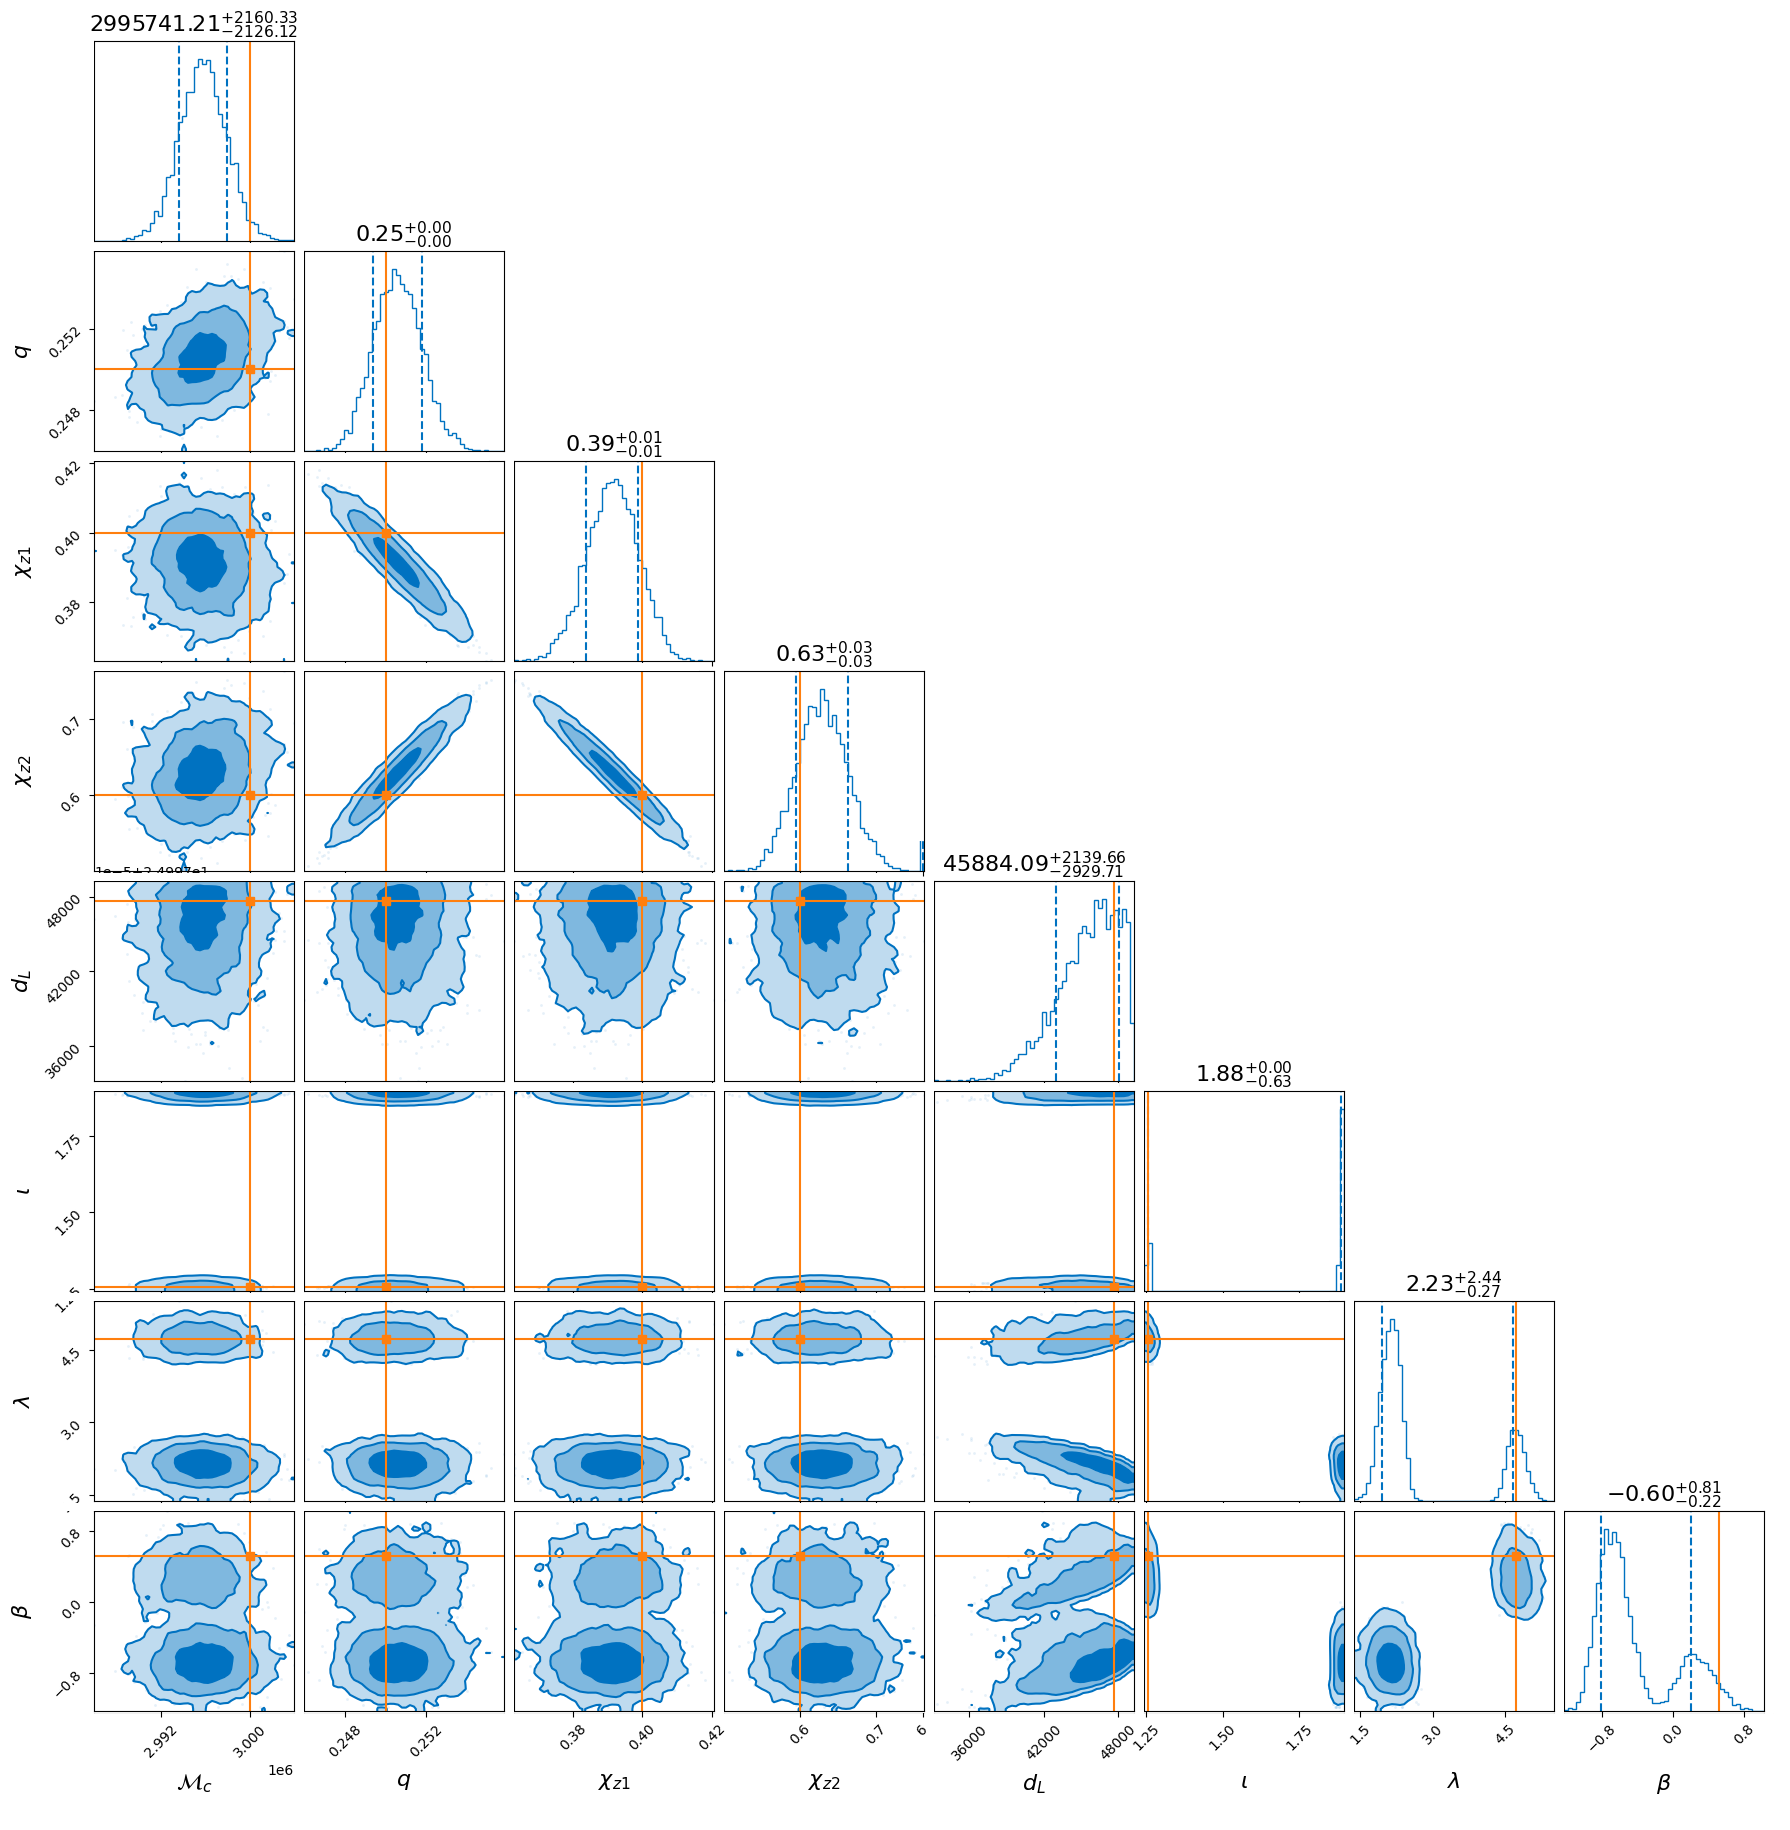

In [10]:
DISPLAY_PARAMETERS = ["chirp_mass", "mass_ratio", "spin_1z", "spin_2z",
                      "luminosity_distance", "inclination", "longitude", "latitude"]
from tutorial_tools.common import BASE
display(Image(filename=str(BASE/"figures/31_mbhb_eight_parameter_posterior.png"), width=1050))

### Optional rerun

In [11]:
import bilby
parameter_names = ["chirp_mass", "mass_ratio", "spin_1z", "spin_2z", "reference_time",
                   "reference_phase", "luminosity_distance", "inclination", "longitude",
                   "latitude", "psi"]

class MBHBLikelihood(bilby.Likelihood):
    def __init__(self, native_likelihood, use_heterodyne=False):
        super().__init__(parameters={name: None for name in parameter_names})
        self.native, self.use_heterodyne = native_likelihood, use_heterodyne

    def log_likelihood(self):
        function = self.native.het_log_like if self.use_heterodyne else self.native.full_log_like
        return float(function(ParamDict2ParamArrFref(self.parameters)))

sampling_likelihood = MBHBLikelihood(full)
sampling_likelihood.parameters.update(fit)
np.testing.assert_allclose(sampling_likelihood.log_likelihood(),
                           full.full_log_like(ParamDict2ParamArrFref(fit)))

### Set physical priors explicitly
All eleven parameters are sampled directly in physical units. Wherever the
search supplies an error estimate, the window is written as a multiple of that
error — five standard deviations around the searched mode — instead of a
literal interval; the cell turns those multiples into numbers.

| parameter | prior | range |
|---|---|---|
| $\mathcal M_c$ | uniform | $\hat{\mathcal M}_c \pm 5\sigma_{\mathcal M_c}$ |
| $q$ | uniform | $\hat q \pm 5\sigma_q$, clipped to $[0.1,\,0.99]$ |
| $\chi_{1z}$ | uniform | $\hat\chi_{1z} \pm 5\sigma_{\chi_{1z}}$, clipped to $[-0.9,\,0.9]$ |
| $\chi_{2z}$ | uniform | $\hat\chi_{2z} \pm 5\sigma_{\chi_{2z}}$, clipped to $[-0.9,\,0.9]$ |
| $t_{\rm ref}$ | uniform | $\hat t_{\rm ref} \pm 5\sigma_{t_{\rm ref}}$ |
| $D_L$ | uniform | $\hat D_L \pm 5\sigma_{D_L}$, clipped to $[6\times10^{3},\,10^{5}]$ Mpc |
| $\iota$ | `Sine($0,\pi$)`: uniform in $\cos\iota$ | isotropic |
| $\beta$ | `Cosine($-\pi/2,\pi/2$)`: $p\propto\cos\beta$ | isotropic sky |
| $\varphi_{\rm ref}$ | uniform, periodic | $[0,2\pi)$ |
| $\lambda$ | uniform, periodic | $[0,2\pi)$ |
| $\psi$ | uniform, periodic | $[0,\pi)$ |

The hat marks the searched mode (`searched_parameters`). The five
$\sigma$'s of the intrinsic parameters are the local Fisher errors in
`original_fisher_errors`, obtained from the native 11-dimensional Fisher matrix
around that mode; the cell multiplies each by five and clips to the physical
limits. $\sigma_{D_L}$ is the distance error of the same Fisher matrix, quoted
in the cell because it is not stored in the JSON. The angles carry no Fisher
window at all: $\iota$ and $\beta$ are isotropic and the phases are periodic
over their full range, which is what leaves the sky and reflection modes free
to appear.

To read the resulting numeric intervals, print `minimum` and `maximum` of each
entry of `priors`. The narrow intrinsic windows make this a **local** analysis
around the searched mode: they keep the sampler near the recovered solution
instead of covering the whole mass–spin space, while the broad angular priors
allow the degeneracies to show.


In [12]:
priors = bilby.core.prior.PriorDict()
limits = {"chirp_mass": (1., np.inf), "mass_ratio": (0.1, 0.99),
          "spin_1z": (-0.9, 0.9), "spin_2z": (-0.9, 0.9),
          "reference_time": (-np.inf, np.inf)}
for name, sigma in meta["original_fisher_errors"].items():
    centre = float(np.asarray(fit[name]).item())
    lo, hi = limits[name]
    priors[name] = bilby.prior.Uniform(max(lo, centre-5*sigma), min(hi, centre+5*sigma), name=name)
distance = float(np.asarray(fit["luminosity_distance"]).item())
priors["luminosity_distance"] = bilby.prior.Uniform(
    max(6000., distance-5*4588.679450408627), min(1e5, distance+5*4588.679450408627),
    name="luminosity_distance")
priors["inclination"] = bilby.prior.Sine(name="inclination")
priors["latitude"] = bilby.prior.Cosine(name="latitude")
for name, upper in [("reference_phase", 2*np.pi), ("longitude", 2*np.pi), ("psi", np.pi)]:
    priors[name] = bilby.prior.Uniform(0, upper, name=name, boundary="periodic")
assert set(priors) == set(sampling_likelihood.parameters)
print("Number of sampled parameters:", len(priors))

Number of sampled parameters: 11


The default sampler uses the **full** likelihood. To use heterodyning
after validation, set
`sampling_likelihood = MBHBLikelihood(like, use_heterodyne=True)`.

In [13]:
if RUN_NESSAI:
    result = bilby.run_sampler(likelihood=sampling_likelihood, priors=priors,
                               sampler="nessai", nlive=1200, stopping=0.1, n_pool=NPROC,
                               pytorch_threads=1,
                               outdir=str(OUTPUT/"mbhb_nessai"), label="student_mbhb",
                               seed=20261108, resume=False, plot=False)
    result.plot_corner(parameters=DISPLAY_PARAMETERS, save=True)
